# **Trabalho Prático 3 - Análise Numérica**

Trabalho realizado pelos alunos do Grupo 19 no âmbito da unidade curricular de Análise Numérica (M2018) — 2024/2025:

Bruno	Manuel	Teixeira	Araújo Nº 202207580\
João Pereira Lobato Nº 202306182\
Pedro	Sebastião	Loureiro Pinto	Bessa Nº 202307026

---


# **Objetivos do Trabalho**

Neste trabalho, temos como objetivo dar uso aos nossos conhecimentos acerca da aproximação numérica através da Interpolação polinomial usando o Método de Lagrange ou o Método de Newton em Diferenças Divididas e Interpolação usando splines lineares ou cúbicos completos ou naturais.

Devemos também ser capazes de comparar a eficácia de métodos diferentes em cada caso dado e identificar e justificar as diferenças existentes entre os resultados de ambos, para além de sabermos também calcular os erros de avaliação de um certo valor em cada um destes métodos.

# **Métodos a utilizar**

Para desenvolver os programas a utilizar neste trabalho, recorremos à linguagem Python, uma vez que era aquela com a qual todos os elementos do grupo estavam mais familiarizados, tendo esta sido lecionada em cadeiras anteriores da Licenciatura em Matemática, para além de ser efetivamente simples e de fácil compreensão e leitura.

Todos os cálculos relevantes foram feitos no caderno e depois passados para o trabalho utilizando um convertor de texto Latex. Os gráficos foram obtidos através do própio programa Python (utilizando matplotlib). Utilizamos também o Geogebra para determinar os máximos das funções trabalhadas nos intervalos pretendidos.

# **Exercício 1**

**1. Na seguinte tabela apresentam-se medições da evaporação da água (em polegadas), numa
estação meterológica em Adelaide, Austrália. Cada medição é uma média, calculada a partir
de leituras diárias, ao longo de um período de 23 anos. As medições mostram que a evaporação diminui gradualmente de janeiro a junho-julho, para aumentar novamente de agosto
a dezembro (as estações são invertidas, no hemisfério sul).**

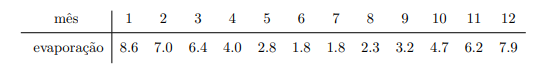

**(a) Construam o polinómio interpolador, p, e o spline cúbico natural, s, daquele conjunto
de pontos e representem graficamente as duas aproximações da função evaporação.**

**(b) Qual das duas aproximações lhes parece mais aceitàvel? Justifiquem.**

a) Construção do polinómio interpolador p do conjunto de pontos dados, utilizando o Método de Lagrange:

Queremos constuir o polinómio interpolador $p_{11}(x)$ = $l_0(x)$$f_0$  +  $l_1(x)$$f_1$  +  ...  +  $l_{11}(x)$$f_{11}$ onde:

$f_k$=$f(x_k$)  𝞚  $l_k(x)$=$\frac{(x-x_0)...(x-x_{k-1})(x-x_{k+1})...(x-x_n)}{(x_k-x_0)...(x_k-x_{k-1})(x_l-x_{k+1})...(x_k-x_n)}$

Os valores de $f_k$ são obtidos diretamente pela tabela dada para os k valores dados ($f_0$=f(1)=8.6 , .... , $f_{11}$=f(12)=7.9)

Quanto aos valores de $l_k$, basta calcular
$
{\displaystyle \prod_{k≠i=0}^{n} \frac{(x-x_i)}{(x_k-x_i)} }
$
para cada k desejado, o que se torna fácil utilizando ciclos em Python.

Temos de seguida o código utilizado para calcular o polinómio interpolador p desejado através do Método de Lagrange, com a Imagem 1 a representar o gráfico obtido pelo mesmo, onde podemos verificar que $p_{11}$($x_i$)=$f_i$  ∀i ϵ{0,1,...,11} (Condições de interpolação)

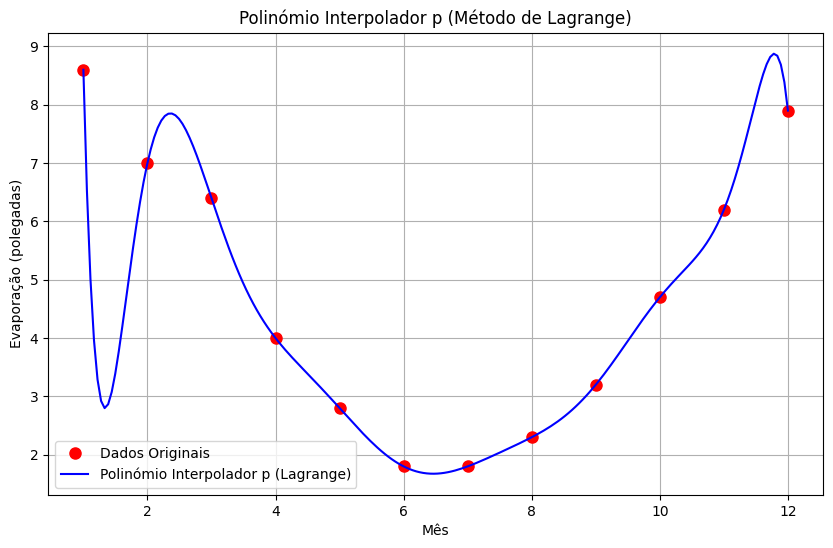

In [ ]:
# Dados de entrada: meses e valores médios de evaporação
x = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
y = [8.6, 7.0, 6.4, 4.0, 2.8, 1.8, 1.8, 2.3, 3.2, 4.7, 6.2, 7.9]

def lagrange_basis(x_points, i, x_val): #Cálculo de l(x)
    """
    Calcula o polinómio base de Lagrange l_i(x) para o índice i.
    """
    L_i = 1
    for j in range(len(x_points)):
        if j != i:
            L_i *= (x_val - x_points[j]) / (x_points[i] - x_points[j])
    return L_i

def lagrange_interpolation(x_points, y_points, x_val):
    """
    Calcula o valor interpolado p(x) usando o método de Lagrange.
    """
    p_x = 0
    for i in range(len(x_points)):
        p_x += y_points[i] * lagrange_basis(x_points, i, x_val)
    return p_x

import numpy as np               # Para cálculos numéricos
import matplotlib.pyplot as plt  # Para visualização gráfica

# Geração de pontos interpolados
x_vals = np.linspace(1, 12, 200)  # 200 pontos entre 1 e 12
y_vals = [lagrange_interpolation(x, y, xi) for xi in x_vals]

# Criação do gráfico
plt.figure(figsize=(10, 6))
plt.plot(x, y, 'o', label='Dados Originais', markersize=8, color='red')              # Pontos originais
plt.plot(x_vals, y_vals, label='Polinómio Interpolador p (Lagrange)', color='blue')  # Curva interpolada
plt.xlabel('Mês')
plt.ylabel('Evaporação (polegadas)')
plt.title('Polinómio Interpolador p (Método de Lagrange)')
plt.legend()
plt.grid(True)
plt.show()



**Imagem 1 - Polinómio interpolador p (Método de Lagrange) :**

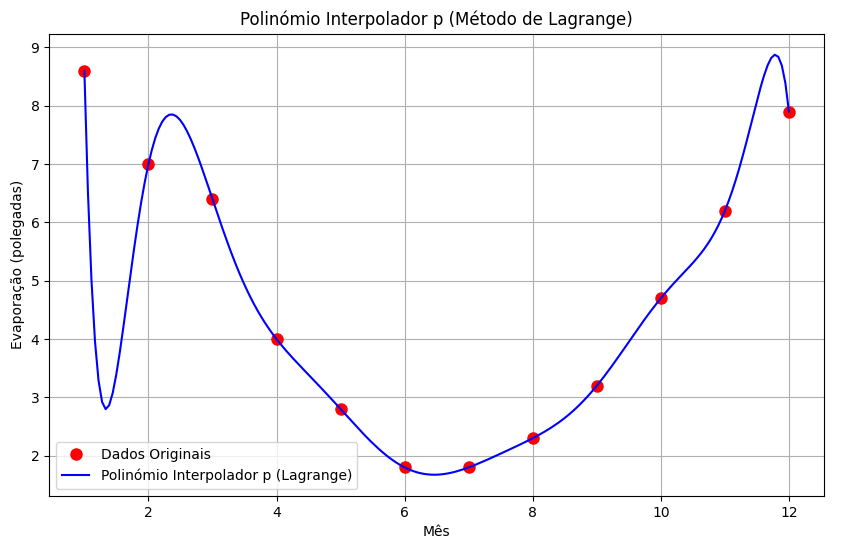

Construção do spline cúbico natural s:

Para construir s, primeiro precisamos de determinar $M_0 , M_1, ..., M_{11}$ (12 incógnitas) através das condiçôes:

$
\frac{h_i}{6}M_{i-1}+\frac{h_i+h_{i+1}}{3}M_i+\frac{h_{i+1}}{6}M_{i+1} = \frac{f_{i+1}-f_i}{h_{i+1}}-\frac{f_i-f_{i-1}}{h_i}\ para\ i=1,2,...,10\$  **(10 condições)**


\

Ora, como queremos que s seja natural, devemos juntar às 10 condições anteriores as seguintes 2:
$ M_0=0 ∧ M_{11}=0 $

Desta forma, temos 12 incógnitas e 12 equações lineares, sendo assim possível determinar o spline através do sistema resolvido no programa seguinte:


In [ ]:
import numpy as np

# Dados iniciais
x = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12])  # Meses
f = np.array([8.6, 7.0, 6.4, 4.0, 2.8, 1.8, 1.8, 2.3, 3.2, 4.7, 6.2, 8.0])  # Evaporação(Polegadas)

# Número de pontos dados (n=12)
n = len(x)

# Cálculo de h_i
h = np.diff(x)

#
A = np.zeros((n-2, n-2))  #Matrix A (10x10) (pois 2 coeficientes já estão definidos)
b = np.zeros(n-2)  # Vetor b de tamanho 10

# matrix A conforme condições iniciais (valores de h_i estão todos com -1 de index do que na fórmula porque começamos com i=1 e não i=0 no ciclo)
for i in range(1, n-1):
    A[i-1, i-1] = (h[i-1] + h[i]) / 3
    if i > 1:
        A[i-1, i-2] = h[i-1] / 6
    if i < n-2:
        A[i-1, i] = h[i] / 6

# Vetor b   (valores de h_i estão todos com -1 de index do que na fórmula porque começamos com i=1 e não i=0 no ciclo)
for i in range(1, n-1):
    b[i-1] = (f[i+1] - f[i]) / h[i] - (f[i] - f[i-1]) / h[i-1]

# Resolver o sistema linear A * M = b
M_inner = np.linalg.solve(A, b)

#Criar Vetor (Com condições M_0 = 0 e M_11 = 0)
M = np.zeros(n)
M[1:-1] = M_inner  #M_0=0 e M_11=0


# Valor dos coeficientes pretendidos
print(" M_i:")
print(M)




 M_i:
[ 0.          2.52274352 -4.0909741   3.04115286 -0.87363733  1.65339647
  0.26005146  0.3063977   0.91435776 -0.36382874  0.54095718  0.        ]


**Imagem 2 - Valores dos coeficientes M0 a M11 :**

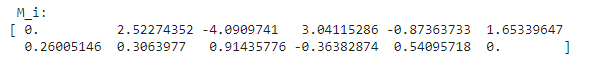

Tendo determinados os coeficientes de $M_0\ a\ M_{11}$ (ver Imagem 2) basta-nos agora substitui-los para cada expressão de $S_i(x)$ dada por:
$
S_i(x)=M_{i-1}\frac{(x_i-x)^3}{6h_i}+M_i\frac{(x-x_{i-1})^3}{6h_i}+(f_{i-1}-M_{i-1}\frac{h_i^2}{6})\frac{x_i-x}{h_i}+(f_i-M_i\frac{h_i^2}{6})\frac{x-x_{i-1}}{h_i}
$ em cada sub-intervalo [$x_{i-1},x_i$] para i=1,2,...,11.

No programa abaixo temos a resolução deste problema e representação gráfica do spline cúbico natural s obtido para os 12 valores dados (Imagem 3).

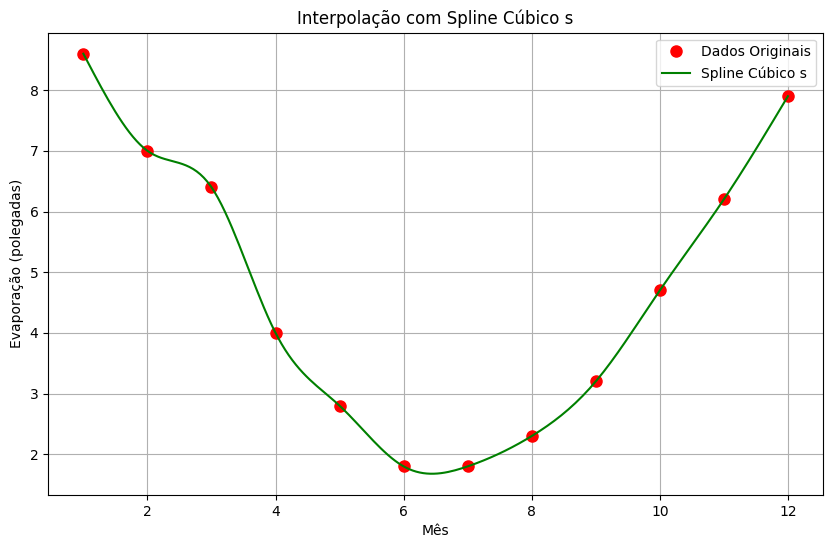

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline

# Dados de entrada: meses e valores médios de evaporação
x = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]  # Meses
y = [8.6, 7.0, 6.4, 4.0, 2.8, 1.8, 1.8, 2.3, 3.2, 4.7, 6.2, 7.9]  # Evaporação

# Criação do spline cúbico natural
spline = CubicSpline(x, y, bc_type='natural')

# Geração de pontos interpolados
x_vals = np.linspace(1, 12, 200)  # 200 pontos entre 1 e 12
y_vals = spline(x_vals)           # Avalia o spline nos novos pontos

# Criação do gráfico
plt.figure(figsize=(10, 6))
plt.plot(x, y, 'o', label='Dados Originais', markersize=8, color='red')  # Pontos originais
plt.plot(x_vals, y_vals, label='Spline Cúbico s', color='green')   # Curva do spline cúbico
plt.xlabel('Mês')
plt.ylabel('Evaporação (polegadas)')
plt.title('Interpolação com Spline Cúbico s')
plt.legend()
plt.grid(True)
plt.show()


**Imagem 3 - Spline Cúbico s:**

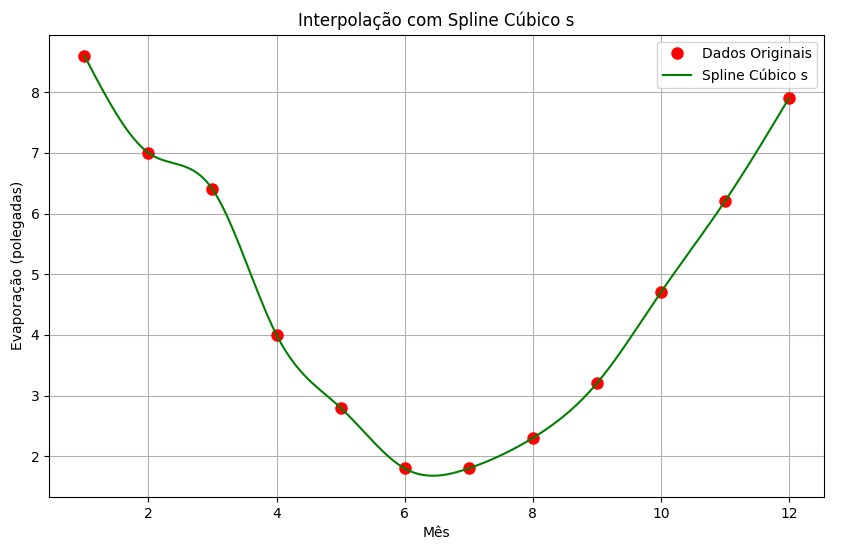

b) Para comparar a eficácia dos dois tipos de aproximação, criamos um programa que apresenta lado a lado os gráficos de p (polinómio interpolador) e de s (spline cúbico natural), pelo que os podemos comparar observando a Imagem 4.

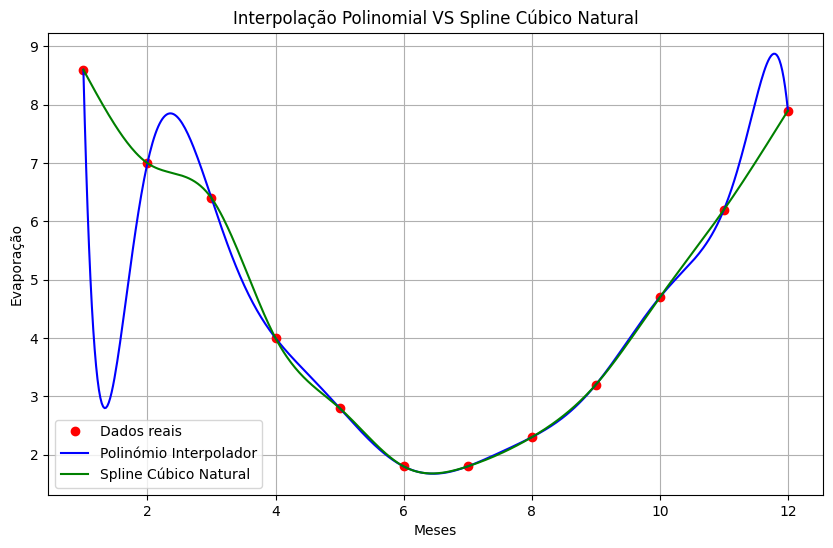

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline, BarycentricInterpolator

# Dados de entrada
x = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12])  # Meses
y = np.array([8.6, 7.0, 6.4, 4.0, 2.8, 1.8, 1.8, 2.3, 3.2, 4.7, 6.2, 7.9])  # Evaporação

# Interpolação polinomial
polinomio_interp = BarycentricInterpolator(x, y)

# Spline cúbico natural (usando CubicSpline do scipy)
spline_cubico = CubicSpline(x, y, bc_type='natural')

# Gerando pontos para o gráfico
x_fino = np.linspace(min(x), max(x), 500)
y_polinomio = polinomio_interp(x_fino)
y_spline = spline_cubico(x_fino)

# Resultados
plt.figure(figsize=(10, 6))

# Dados reais
plt.plot(x, y, 'ro', label='Dados reais')

# Polinómio interpolador
plt.plot(x_fino, y_polinomio, label='Polinómio Interpolador', linestyle='-',color='blue')

# Spline cúbico natural
plt.plot(x_fino, y_spline, label='Spline Cúbico Natural', linestyle='-',color='green')

# Adicionar legenda e título
plt.title('Interpolação Polinomial VS Spline Cúbico Natural')
plt.xlabel('Meses')
plt.ylabel('Evaporação')
plt.legend()

# Exibir o gráfico
plt.grid(True)
plt.show()


**Imagem 4 - Comparação dos gráficos de p e s:**

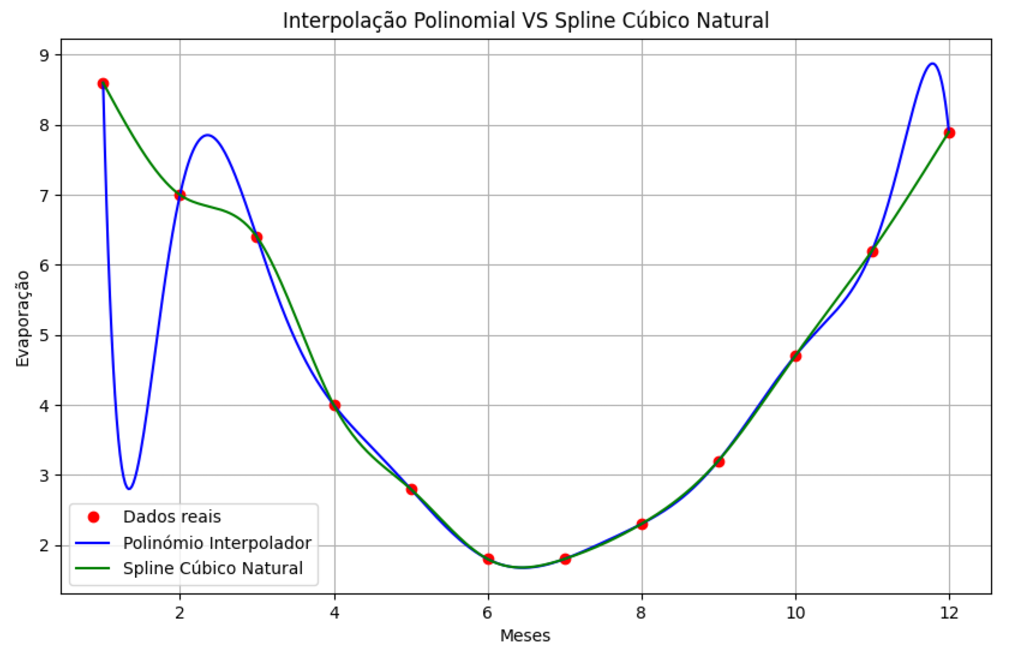

Podemos observar pela Imagem 4 que o gráfico de s é muito mais "suave" e apresenta menores oscilações entre cada valor dado, sendo por isso aquele que representa uma melhor aproximação numérica dos dados recebidos.

 Isto deve-se ao facto de, tal como é afirmado no exemplo de Runge, se verificar que para valores de x (igualmente espaçados) mais afastados do ponto médio das abcissas de interpolação termos que o valor de $π_{n+1}$(x) apresenta um erro maior.

 De facto, podemos observar pelo gráfico de p que este apresenta maiores oscilações nas abcissas mais próximas dos extremos do intervalo dado [1,12].

 Deste modo, podemos concluir que neste caso a interpolação por spline cúbico natural do conjunto de valores dados é mais precisa do que aquele efetuada através de um polinómio interpolador.

# **Exercício 2**

**2. Considerem a função f(x) = $x − cos(x)^3$, para −3 ≤ x ≤ 3**

**(a) Construam um conjunto de n+1=7 pontos, ($x_i$
, $f_i$=$f(x_i))^n_{i=0}$, de abcissas $x_i$, i=0, . . . , n igualmente espaçadas no intervalo [−3, 3];**

**(b) Construam o polinómio interpolador, p, e o spline cúbico natural, s, de f naquele conjunto de pontos;**

**(c) Comparem os gráficos das aproximações p e s com o de f no intervalo dado, e comparem os gráficos das funções erro |f − p| e |f − s|;**

**(d) Calculem majorantes dos erros cometidos ao estimar f(0.1) e f(2.6) usando o polinómio interpolador e o spline calculados;**

**(e) Comentem os resultados obtidos.**

a) Podemos por exemplo escolher $x_0$ = -3 com espaçamento de 1 entre cada abcissa seguinte. Temos assim o intervalo [-3,3] dividido por 7 pontos igualmente espaçados como pretendido.

De seguida apresentamos o código que nos calcula o valor de $f_i$ para cada i, expondo os resultados na forma de uma tabela (ver Imagem 5).

In [ ]:
import numpy as np

# Definir a função f(x) = x - cos^3(x)
def f(x):
    return x - np.cos(x)**3

# Cria os 7 pontos igualmente espaçados (intervalo [-3, 3])
x_values = np.linspace(-3, 3, 7)

# Cálculo dos valores correspondentes
f_values = f(x_values)

# Imprimir a tabela com os resultados desejados
print(f"{'x_i':<10} {'f(x_i)':<20}")
print("-" * 23)
for x, fx in zip(x_values, f_values):
    print(f"{x:<10.2f} {fx:<20.6f}")


x_i        f(x_i)              
-----------------------
-3.00      -2.029723           
-2.00      -1.927932           
-1.00      -1.157729           
0.00       -1.000000           
1.00       0.842271            
2.00       2.072068            
3.00       3.970277            


**Imagem 5 - Resultados de $x_i$ e de $f_i$:**

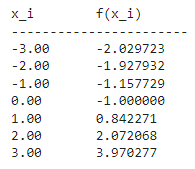

b) Construção do polinómio interpolador p no cojunto de pontos escolhidos:

\

Tal como já fizemos na alínea a) do exercício 1, p é determinado por: $p_{6}(x)$ = $l_0(x)$$f_0$  +  $l_1(x)$$f_1$  +  ...  +  $l_{6}(x)$$f_{6}$ onde:


$f_k$=$f(x_k$)  𝞚  $l_k(x)$=$\frac{(x-x_0)...(x-x_{k-1})(x-x_{k+1})...(x-x_n)}{(x_k-x_0)...(x_k-x_{k-1})(x_l-x_{k+1})...(x_k-x_n)}$

\

Os valores de $f_k$ são obtidos pelos cálculos realizados na alínea anterior para cada k  ($f_0$=f(-3.00)=-2.029723 , .... , $f_{6}$=f(3.00)=3.970277) (ver Imagem 5).

Quanto aos valores de $l_k$, basta calcular
$
{\displaystyle \prod_{k≠i=0}^{n} \frac{(x-x_i)}{(x_k-x_i)} }
$
para cada k desejado através de um programa Python, tal como foi feito em 1-a).

\

Temos de seguida o código utilizado para calcular o polinómio interpolador p desejado através do Método de Lagrange, com a Imagem 6 a representar o gráfico obtido pelo mesmo, onde podemos verificar que $p_{6}$($x_i$)=$f_i$  ∀i ϵ{0,1,...,6} (Condições de interpolação)

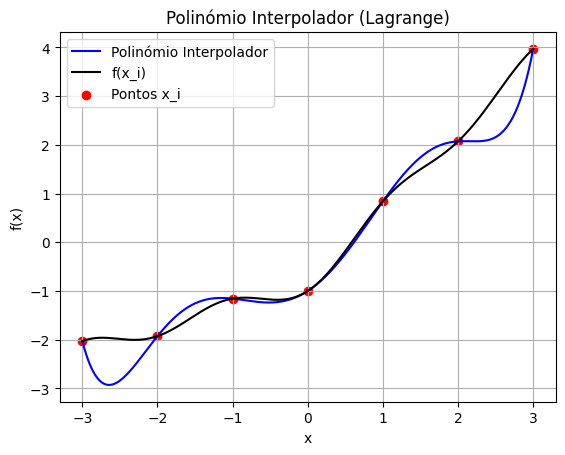

In [ ]:
import math
import matplotlib.pyplot as gr

def f(x):
    return x - math.cos(x)**3

pontos_x = [-3, -2, -1, 0, 1, 2, 3]
pontos_y = [f(x) for x in pontos_x]

def interpolacao(pontos_x, pontos_y, x):
    n = len(pontos_x)
    pl = 0


    for i in range(n):
        termo = 1
        for k in range(n):
            if k != i:
                termo *= (x - pontos_x[k]) / (pontos_x[i] - pontos_x[k])  #cálculo de cada l_k
        pl += pontos_y[i] * termo    #cálculo do valor de p_6(x) (vamos multiplicando por cada l_k e f_k)

    return pl

vals_x = [x / 100 for x in range(-300, 301)]
vals_y = [interpolacao(pontos_x, pontos_y, x) for x in vals_x]
f_x =[x-math.cos(x)**3 for x in vals_x]

gr.plot(vals_x, vals_y, label='Polinómio Interpolador', color='blue')
gr.plot(vals_x , f_x, label = "f(x_i)",color = "black" )
gr.scatter(pontos_x, pontos_y, color='red', label='Pontos x_i',)
gr.title('Polinómio Interpolador (Lagrange)')
gr.xlabel('x')
gr.ylabel('f(x)')
gr.legend()
gr.grid(True)
gr.show()

**Imagem 6 - Gráfico do Polinómio Interpolador p (Método de Lagrange):**

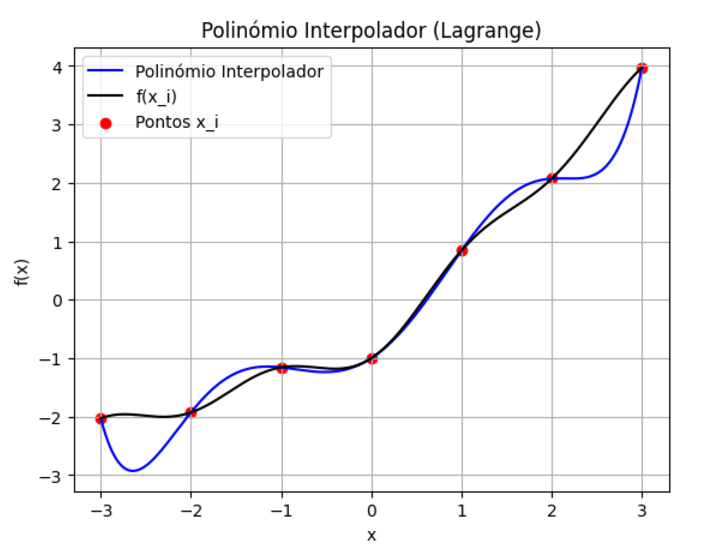

Construção do Spline Cúbico Natural s:

Analogamente a 1-a) o spline s fica determinado por um sistema de 7 equações lineares :

$
\frac{h_i}{6}M_{i-1}+\frac{h_i+h_{i+1}}{3}M_i+\frac{h_{i+1}}{6}M_{i+1} = \frac{f_{i+1}-f_i}{h_{i+1}}-\frac{f_i-f_{i-1}}{h_i}\ para\ i=1,2,...,5\ $  **(5 condições)**

$ M_0=0 ∧ M_{6}=0 $  $ \ $ **(2 condições - definição de spline cúbico natural)**

\

Tendo determinados os coeficientes de $M_0\ a\ M_{6}$  basta-nos agora substitui-los para cada expressão de $S_i(x)$ dada por:
$
S_i(x)=M_{i-1}\frac{(x_i-x)^3}{6h_i}+M_i\frac{(x-x_{i-1})^3}{6h_i}+(f_{i-1}-M_{i-1}\frac{h_i^2}{6})\frac{x_i-x}{h_i}+(f_i-M_i\frac{h_i^2}{6})\frac{x-x_{i-1}}{h_i}
$ em cada sub-intervalo [$x_{i-1},x_i$] para i=1,2,...,6.

\

Segue abaixo um programa que nos permite determinar e representar graficamente o spline cúbico natural s (ver Imagem 7).


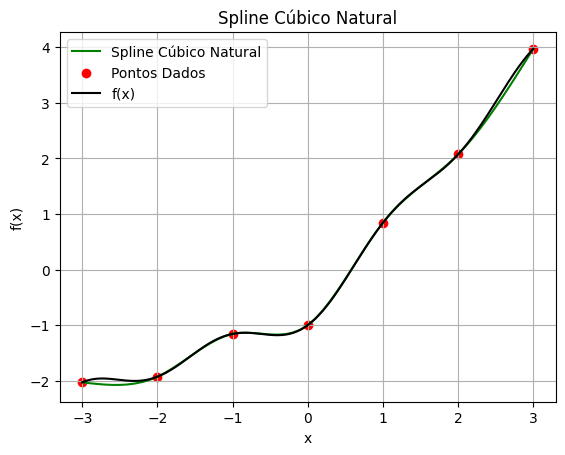

In [ ]:
import math
import numpy as np
import matplotlib.pyplot as gr

# Função dada
def f(x):
    return x - math.cos(x)**3

# Pontos de interpolação
pontos_x = [-3, -2, -1, 0, 1, 2, 3]
pontos_y = [f(x) for x in pontos_x]

# Número de pontos (7)
n = len(pontos_x)

# Calcular as diferenças
h = [pontos_x[i+1] - pontos_x[i] for i in range(n-1)]  # Diferença entre os pontos x

# Matriz para o sistema de equações
A = np.zeros((n, n))
b = np.zeros(n)

# Preencher a matriz A e o vetor b para resolver o sistema para M_i (segunda derivada em x_i)
# (Multiplicamos ambos os lados da equação por 6 para simplificar fórmula)
for i in range(1, n-1): #(valores de h_i estão todos com -1 de index do que na fórmula porque começamos com i=1 e não i=0 no ciclo)
    A[i][i-1] = h[i-1]  #M_(i-1)
    A[i][i] = 2 * (h[i-1] + h[i]) #M_i
    A[i][i+1] = h[i]    #M_(i+1)
    b[i] = 6 * ((pontos_y[i+1] - pontos_y[i]) / h[i] - (pontos_y[i] - pontos_y[i-1]) / h[i-1])

# Condições para o spline cúbico natural: S''(x0) = 0 e S''(xn) = 0
A[0][0] = 1
A[n-1][n-1] = 1

# Resolver o sistema para M_i (segunda derivada)
M = np.linalg.solve(A, b)

# Função que calcula o spline desejado
def spline(x):
    # Encontrar o intervalo em que x está
    for i in range(n-1):
        if pontos_x[i] <= x <= pontos_x[i+1]:
            h_i = pontos_x[i+1] - pontos_x[i]  # Comprimento do intervalo
            # Fórmula do spline cúbico (M_i tem +1 no index do que na fórmula por termos começado com i=1 e não 0)
            return (M[i] * (pontos_x[i+1] - x)**3 / (6 * h_i) +
                    M[i+1] * (x - pontos_x[i])**3 / (6 * h_i) +
                    (pontos_y[i] - M[i] * h_i**2 / 6) * (pontos_x[i+1] - x) / h_i +
                    (pontos_y[i+1] - M[i+1] * h_i**2 / 6) * (x - pontos_x[i]) / h_i)
    return None  # Caso x não esteja no intervalo (Exceção)

# Gerar valores de x para o gráfico
x_vals = [x / 10.0 for x in range(-30, 31)]  # Gera valores de -3 a 3 com intervalo 0.1
y_vals = [spline(x) for x in x_vals]         # Cálculo do valor do spline para cada x

# Representação gráfica dos pontos originais e do spline cúbico natural
gr.plot(x_vals, y_vals, label='Spline Cúbico Natural', color='green')  # Linha do spline
gr.scatter(pontos_x, pontos_y, color='red', label='Pontos Dados')      # Pontos x_i

# Plotar a função f(x) original para comparação
vals_x = [x / 100 for x in range(-300, 301)]
f_x = [f(x) for x in vals_x]
gr.plot(vals_x, f_x, label="f(x)", color="black")

# Adicionar título e legenda ao gráfico
gr.title('Spline Cúbico Natural')
gr.xlabel('x')
gr.ylabel('f(x)')
gr.legend()

# Exibir o gráfico
gr.grid(True)
gr.show()



**Imagem 7 - Gráfico do Spline Cúbico Natural s:**

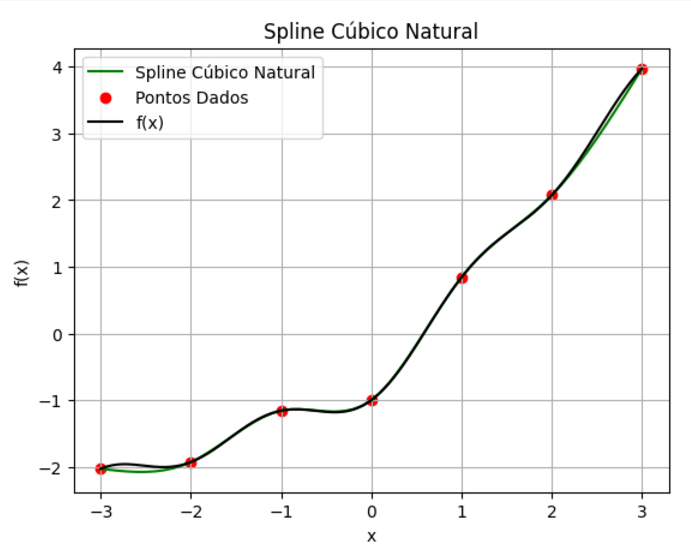

c) Comparação de f(x) com o spline cúbico natural **s** e o polinómio interpolador **p**:

Abaixo temos um programa que nos permite representar os gráficos de p, s e f(x),que podemos comparar pela Imagem 8 e cujos resultados iremos comentar na alínea e).

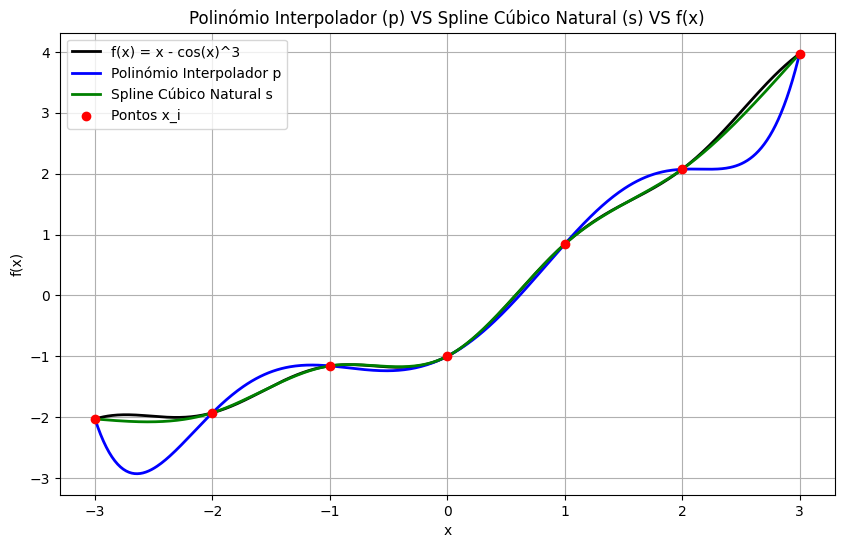

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline

# Definir a função f(x) a ser aproximada
def f(x):
    return x - np.cos(x)**3

# Dados fornecidos
pontos_x = [-3, -2, -1, 0, 1, 2, 3]
pontos_y = [f(x) for x in pontos_x]


x_fino = np.linspace(-3.0, 3.0, 500)

# Polinómio Interpolador
coeficientes = np.polyfit(pontos_x, pontos_y, deg=len(pontos_x)-1)  # Ajustar um polinómio de grau len(pontos_x)-1
interp_polinomio = np.polyval(coeficientes, x_fino)

# Interpolação Spline Cúbica Natural
spline_cubico = CubicSpline(pontos_x, pontos_y, bc_type='natural')
interp_spline = spline_cubico(x_fino)

# Valores verdadeiros da função (para comparação)
valores_verdadeiros = f(x_fino)

# Apresentação das 3 funções
plt.figure(figsize=(10, 6))


plt.plot(x_fino, valores_verdadeiros, label='f(x) = x - cos(x)^3', color='black', linestyle='-', linewidth=2)

plt.plot(x_fino, interp_polinomio, label='Polinómio Interpolador p', color='blue', linestyle='-', linewidth=2)


plt.plot(x_fino, interp_spline, label='Spline Cúbico Natural s', color='green', linestyle='-', linewidth=2)


plt.scatter(pontos_x, pontos_y, color='red', zorder=5, label='Pontos x_i')

# Adicionar título e legenda
plt.xlabel('x')
plt.ylabel('f(x)')
plt.title('Polinómio Interpolador (p) VS Spline Cúbico Natural (s) VS f(x)')
plt.legend()
plt.grid(True)
plt.show()


**Imagem 8 - Comparação entre p, s e f(x):**

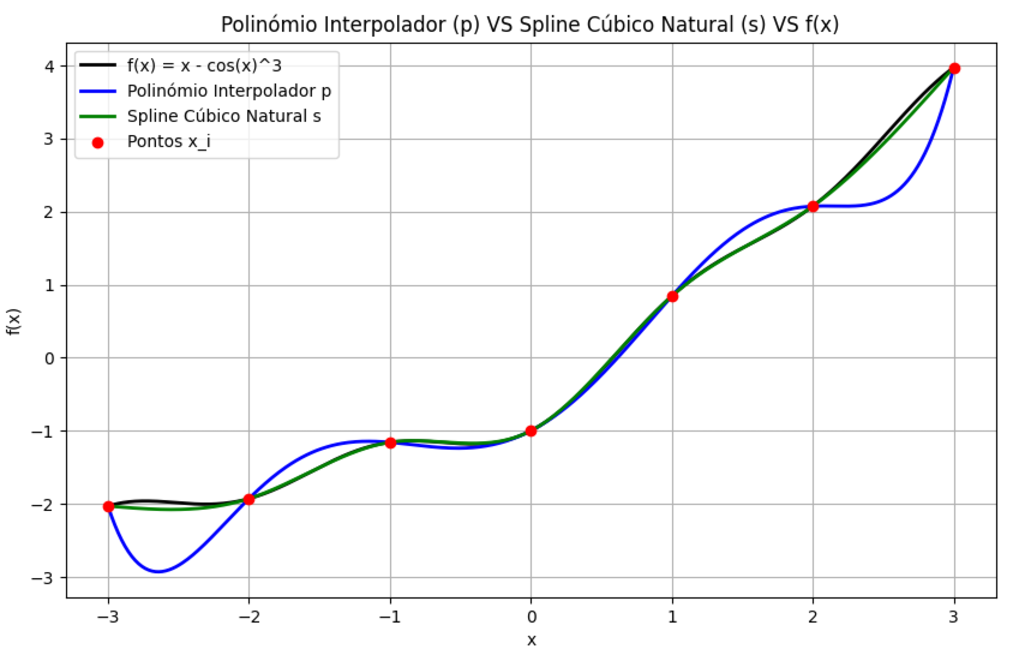

De seguida, temos um programa que nos permite representar os gráficos das funções erro |f − p| e |f − s|, que podemos comparar pela Imagem 9 e cujos resultados iremos discutir na alínea e).


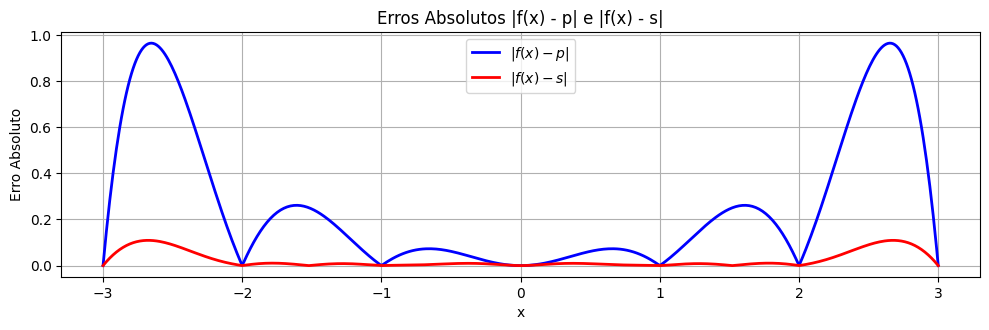

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline

# Definir a função f(x)
def f(x):
    return x - np.cos(x)**3

# Dados fornecidos
pontos_x = [-3, -2, -1, 0, 1, 2, 3]
pontos_y = [f(x) for x in pontos_x]

x_fino = np.linspace(-3.0, 3.0, 500)

# Polinómio Interpolador
coeficientes = np.polyfit(pontos_x, pontos_y, deg=len(pontos_x)-1)
interp_polinomio = np.polyval(coeficientes, x_fino)

# Interpolação - Spline Cúbica Natural
spline_cubico = CubicSpline(pontos_x, pontos_y, bc_type='natural')
interp_spline = spline_cubico(x_fino)

# Valores verdadeiros da função (para comparação)
valores_verdadeiros = f(x_fino)

# Cálculo dos erros absolutos |f(x) - p(x)| e |f(x) - s(x)|
erro_p = np.abs(valores_verdadeiros - interp_polinomio)
erro_s = np.abs(valores_verdadeiros - interp_spline)

# Apresentação das 3 funções + erros absolutos
plt.figure(figsize=(10, 6))

# Gráfico dos erros absolutos
plt.subplot(2, 1, 2)
plt.plot(x_fino, erro_p, label=r'$|f(x) - p|$', color='blue', linestyle='-', linewidth=2)
plt.plot(x_fino, erro_s, label=r'$|f(x) - s|$', color='red', linestyle='-', linewidth=2)
plt.xlabel('x')
plt.ylabel('Erro Absoluto')
plt.title('Erros Absolutos |f(x) - p| e |f(x) - s|')
plt.legend()
plt.grid(True)

# Mostrar os gráficos
plt.tight_layout()
plt.show()


**Imagem 9 - Comparação entre |f-s| e |f-p|:**

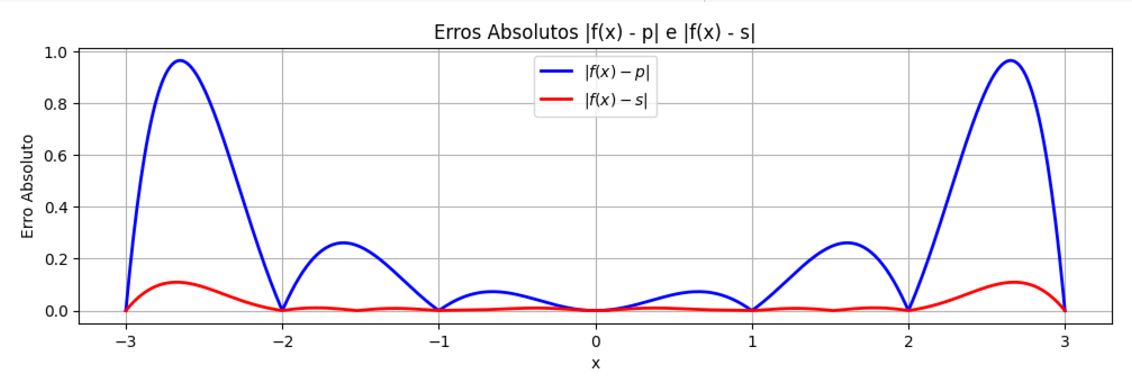

d) Temos agora de calcular um majorante do erro ao avaliar f(0.1) e f(2.6) usando ambos os Métodos das alíneas anteriores.

Primeiramente, calculemos f(0.1) e f(2.6)

In [ ]:
import math

#Função f(x)
def f(x):
  return x-math.cos(x)**3
print("f(0.1)= ",f(0.1))
print("f(2.6)= ",f(2.6))

f(0.1)=  -0.885087246239921
f(2.6)=  3.2291777098860486


Pelo código anterior e fixando 6 casas decimais, temos que:

$f(0.1)=-0.885087  \ \ 𝝠 \  \ f(2.6)=3.229178  $



Para calcular o majorante do erro cometido na avaliação de f(0.1) e de f(2.6) usando o Método de Lagrange na construção de um polinómio interpolador p iremos utilizar a seguinte fórmula:

$
|f(x)-p(x)|≤ \frac{M}{(n+1)!}|(x-x_0)(x-x_1)...(x-x_n)|
$

$onde\ M = max_{x𝝐I}|f^{(n+1)}(x)|$

Neste caso, temos n+1=7 pontos logo n=6, pelo que para determinar M teremos de determinar a derivada de ordem 7 de f(x) (o que é possível pois f(x) é de classe $C^∞$) e seguidamente o seu máximo no intervalo I=[-3,3]

Iremos determinar M com recurso às capacidades gráficas do Geogebra e seguidamente exibiremos um programa que nos permite calcular o majorante do erro cometido na avaliação de ambos os valores desejados.

Ora, podemos manualmente calcular $f^{(7)}(x)$ = $546sen^3(x)-1641cos^2(x)sen(x)$

**Imagem 10 - Cálculo de M:**

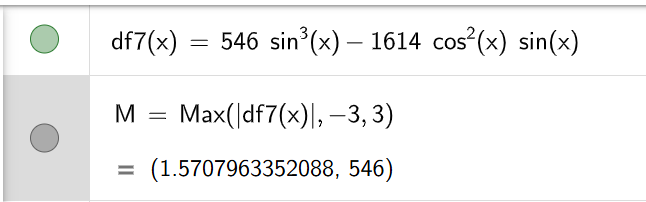

In [ ]:

def factorial(k): #função recursiva para definir fatorial a usar no cálculo de E(x)
    if k < 2:
        return 1
    else:
        return k * factorial(k-1)

# Valor de M
M =546

#Valor de n
n=6

def E(x): #Majorante do erro na avaliação de f(x) pelo polinómio interpolador p
  n1=M
  n2=(x+3)*(x+2)*(x+1)*(x-0)*(x-1)*(x-2)*(x-3)
  den=factorial(n+1)
  return (n1*abs(n2))/(den)  #fórmula do majorante do erro

print("Majorante do erro cometido na avaliação de f(0.1) por p:",E(0.1))
print("Majorante do erro cometido na avaliação de f(2.6) por p:",E(2.6))


Majorante do erro cometido na avaliação de f(0.1) por p: 0.3847068225000001
Majorante do erro cometido na avaliação de f(2.6) por p: 10.03032576


**Imagem 11 - Majorantes dos erros cometidos na avaliação de f(0.1) e f(2.6) por p:**

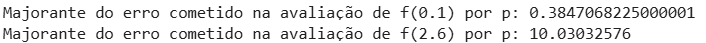

Assim, arredondando por excesso os majorantes dos erros cometidos na avaliação dos pontos pedidos (ver Imagem 11) temos:

$ f(0.1)= -0.89 ± 3.85×10^{-1} \ \ \ 𝞚 \ \ \ \ f(2.6)=3,3 ± 1,01×10^1$


Para calcular um majorante do erro na avaliação de f(0.1) e de f(2.6) pelo Spline Cúbico Natural s, devemos primeiro averiguar se f 𝞊 $C^4$.

Ora, f(x) é a composição de um polinómio e de uma função trignométrica. Como ambos estes tipos de funções são de classe $C^∞$, podemos concluir que f 𝞊 $C^4$. (Ou podemos calcular $f^4$(x)=60cos(x)$sen^2(x)$ - 21$cos^3$(x) e verificar que esta derivada de ordem 4 é sem dúvida contínua, por se tratar da composição de funções contínuas).

\

Deste modo, sendo f 𝞊 $C^4$ e s(x) o nosso spline cúbico natural s, temos:


$
|f(x)-s(x)|≤ \frac{5}{384}Mh^4
$


onde M = $max_{x𝞊[a,b]}|f^{(4)}(x)|$ e h = $max \ h_i, i=1,2,...,n$

\
Neste caso, [a,b] é o intervalo [-3,3] e n=6

Como o intervalo está dividido por n+1=7 pontos igualmente espaçados por 1, o valor máximo de $h_i$ será 1. Por outro lado, para determinar M utilizamos as funções disponíveis no Geogebra (ver Imagem 12).

Assim, tendo determinados M e h, podemos determinar um majorante do erro (ver Imagem 12).


**Imagem 12 - Cálculo de M e do majorante do erro na avaliação dos pontos f(0.1) e f(2.6) pelo spline s:**

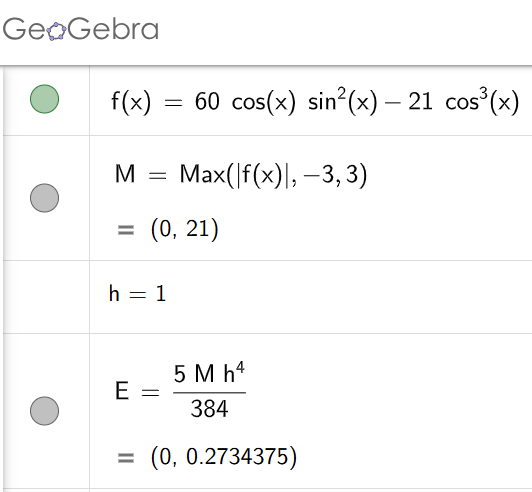

Assim, arredondando o majorante do erro por excesso, temos como resultado que:

$
f(0.1) = -0.89 ± 2.74 × 10^{-1} \ \ \ 𝞚 \ \ \ \ f(2.6) = 3.23 ± 2.74 × 10^{-1}
$

e) Pelos resultados obtidos em c) e d), podemos observar que o spline cúbico natural s é uma aproximação mais precisa de f(x) do que o polinómio interpolador p (pelo método de Lagrange).

Pela Imagem 9, podemos efetivamente notar que a função erro |f-p| toma valores consideravelmente superiores aos da função erro |f-s| ao longo do intervalo, com algumas oscilações notáveis ao longo do mesmo.

Por outro lado, os resultados obtidos em d) mostram-nos que os majorantes dos erros cometidos na avaliação por p e s dos valores f(0.1) e f(2.6) são muito menores em s do que em p, o que novamente realça a maior precisão da utilização do spline cúbico natural s para este caso.

Este fenómeno pode ser explicado pela presença da fator $(x-x_0)(x-x_1)...(x-x_n)$ no cálculo do comportamento do erro para o polinómio interpolador p. Quando avaliamos muitos pontos igualmente espaçados esse mesmo fator tende a acumular vários erros de aproximação, que se propagam assim rapidamente, o que resulta em casos onde o majorante do erro cometido é muito superior ao que pretendiamos, tal como aconteceu em d), especialmente na avaliação de f(2.6).

É importante notar também as diferenças registadas ao calcular os majorantes dos erros cometidos ao avaliar f(0.1) e f(2.6) em p. Tal como já foi referido, f(2.6) apresentou um erro muito maior do que f(0.1).

Isto pode ser explicado através do Exemplo de Runge, que afirma que para abcissas igualmente espaçadas o erro de interpolacão será menor para valores de x mais próximos do ponto medio das abcissas de interpolação. Ora, o ponto médio das 7 abcissas [-3.0, -2.0 , -1.0 , 0, 1.0, 2.0, 3.0] é 0, sendo também óbvio que 0.1 se encontra mais próximo de 0 do que 2.6. Portanto, tal como afirma este fenómeno, é natural que o erro seja maior na avaliação de f(2.6) como observamos nos nossos resultados.









